# Loan Approval Prediction System
**Infobharat Interns - Machine Learning Internship Project**

This notebook builds a system that predicts whether a loan application should be **Approved** or **Rejected**.

**Steps:** 1. Create data, 2. Clean data, 3. Explore (EDA), 4. Visualize, 5. Train models, 6. Evaluate, 7. Predict

## 1. Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)

sns.set_theme(style="whitegrid")

## 2. Create the Synthetic Dataset
1,800 applicants with realistic relationships: higher credit score and income raise approval chances; heavy repayments, more existing loans and unemployment reduce them. A few missing values and duplicates are added on purpose so the cleaning step has real work to do.

In [2]:
np.random.seed(42)
n = 1800

gender = np.random.choice(["Male", "Female"], n)
age = np.random.randint(21, 66, n)
employment = np.random.choice(["Employed", "Self-Employed", "Unemployed"], n, p=[0.60, 0.25, 0.15])
property_area = np.random.choice(["Urban", "Semi-Urban", "Rural"], n, p=[0.40, 0.35, 0.25])

# Income depends on employment
income = np.where(employment == "Employed", np.random.normal(55000, 15000, n),
         np.where(employment == "Self-Employed", np.random.normal(60000, 25000, n),
                  np.random.normal(15000, 6000, n)))
income = np.clip(income, 8000, 200000).round(-2)

credit_score = np.clip(np.random.normal(690, 85, n), 300, 900).round().astype(int)
existing_loans = np.random.choice([0, 1, 2, 3, 4], n, p=[0.35, 0.30, 0.20, 0.10, 0.05])
loan_term = np.random.choice([12, 24, 36, 48, 60, 84, 120, 180, 240], n)
loan_amount = np.clip(income * np.random.uniform(3, 20, n), 50000, 5000000).round(-3)

# Approval rule
emi_ratio = (loan_amount / loan_term) / income
score = ((credit_score - 650) / 50 + (income - 40000) / 30000 - 2.5 * emi_ratio
         - 0.6 * existing_loans
         + np.where(employment == "Employed", 0.8, np.where(employment == "Self-Employed", 0.3, -2.0))
         + np.where(property_area == "Urban", 0.3, np.where(property_area == "Semi-Urban", 0.1, -0.2))
         + np.random.normal(0, 0.8, n) + 0.3)
loan_approved = (np.random.rand(n) < 1 / (1 + np.exp(-score))).astype(int)

df = pd.DataFrame({
    "ApplicantID": np.arange(1001, 1001 + n), "Gender": gender, "Age": age,
    "MonthlyIncome": income, "LoanAmount": loan_amount, "CreditScore": credit_score,
    "EmploymentStatus": employment, "ExistingLoans": existing_loans, "LoanTerm": loan_term,
    "PropertyArea": property_area, "LoanApproved": loan_approved,
})

# Add dirty data on purpose: missing values and duplicates
for col in ["MonthlyIncome", "CreditScore", "Gender"]:
    idx = np.random.choice(df.index, 20, replace=False)
    df.loc[idx, col] = np.nan
df = pd.concat([df, df.sample(15, random_state=1)], ignore_index=True)

df.to_csv("loan_data.csv", index=False)
print("Shape:", df.shape)
df.head()

Shape: (1815, 11)


,ApplicantID,Gender,Age,MonthlyIncome,LoanAmount,CreditScore,EmploymentStatus,ExistingLoans,LoanTerm,PropertyArea,LoanApproved
0,1001,Male,43,21000.0,188000.0,721.0,Self-Employed,0,36,Rural,1
1,1002,Female,41,34900.0,238000.0,617.0,Employed,1,48,Urban,0
2,1003,Male,39,70900.0,1172000.0,661.0,Employed,2,48,Urban,0
3,1004,Male,39,66800.0,1317000.0,900.0,Self-Employed,1,84,Semi-Urban,1
4,1005,Male,56,48300.0,166000.0,693.0,Employed,3,12,Urban,1


## 3. Data Preprocessing

In [3]:
print("Missing values per column:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())

Missing values per column:
ApplicantID          0
Gender              20
Age                  0
MonthlyIncome       21
LoanAmount           0
CreditScore         20
EmploymentStatus     0
ExistingLoans        0
LoanTerm             0
PropertyArea         0
LoanApproved         0
dtype: int64

Duplicate rows: 15


In [4]:
# Remove duplicates
df = df.drop_duplicates()

# Fill missing values: median for numbers, most common value for text
df["MonthlyIncome"] = df["MonthlyIncome"].fillna(df["MonthlyIncome"].median())
df["CreditScore"] = df["CreditScore"].fillna(df["CreditScore"].median()).astype(int)
df["Gender"] = df["Gender"].fillna(df["Gender"].mode()[0])

# Data validation: keep only sensible rows
before = len(df)
df = df[
    df["Age"].between(18, 70) & df["CreditScore"].between(300, 900)
    & (df["MonthlyIncome"] > 0) & (df["LoanAmount"] > 0) & (df["LoanTerm"] > 0)
    & (df["ExistingLoans"] >= 0) & df["LoanApproved"].isin([0, 1])
    & df["EmploymentStatus"].isin(["Employed", "Self-Employed", "Unemployed"])
    & df["PropertyArea"].isin(["Urban", "Semi-Urban", "Rural"])
    & df["Gender"].isin(["Male", "Female"])
]
print("Invalid rows removed:", before - len(df))
print("Missing values left:", int(df.isnull().sum().sum()))
print("Duplicates left:", int(df.duplicated().sum()))
print("Cleaned shape:", df.shape)
df.to_csv("loan_data_cleaned.csv", index=False)

Invalid rows removed: 0
Missing values left: 0
Duplicates left: 0
Cleaned shape: (1800, 11)


## 4. Exploratory Data Analysis (EDA)

In [5]:
print("Overall approval rate: %.1f%%" % (df["LoanApproved"].mean() * 100))

print("\nAverage values: Rejected (0) vs Approved (1)")
display(df.groupby("LoanApproved")[["MonthlyIncome", "CreditScore", "LoanAmount", "ExistingLoans"]].mean().round(0))

print("Approval rate (%) by employment status")
display((df.groupby("EmploymentStatus")["LoanApproved"].mean() * 100).round(1))

print("Approval rate (%) by credit score range")
bands = pd.cut(df["CreditScore"], [299, 600, 700, 800, 900], labels=["300-600", "601-700", "701-800", "801-900"])
display((df.groupby(bands, observed=True)["LoanApproved"].mean() * 100).round(1))

Overall approval rate: 56.5%

Average values: Rejected (0) vs Approved (1)


,MonthlyIncome,CreditScore,LoanAmount,ExistingLoans
LoanApproved,,,,
0,41694.0,651.0,490625.0,1.0
1,57080.0,722.0,647625.0,1.0


Approval rate (%) by employment status


EmploymentStatus
Employed         63.4
Self-Employed    65.9
Unemployed       13.8
Name: LoanApproved, dtype: float64

Approval rate (%) by credit score range


CreditScore
300-600    20.5
601-700    50.0
701-800    70.3
801-900    87.6
Name: LoanApproved, dtype: float64

## 5. Visualizations

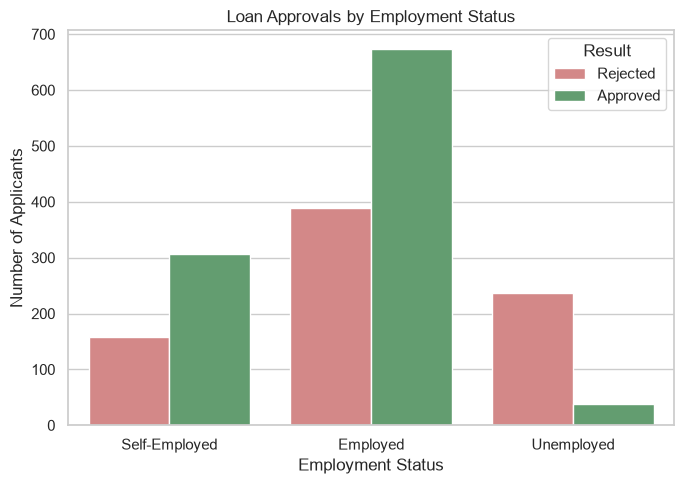

In [6]:
# Chart 1: Loan approvals by employment status
plt.figure(figsize=(7, 5))
ax = sns.countplot(data=df, x="EmploymentStatus", hue="LoanApproved", palette={0: "#e07b7b", 1: "#5aa66b"})
ax.set_title("Loan Approvals by Employment Status")
ax.set_xlabel("Employment Status")
ax.set_ylabel("Number of Applicants")
ax.legend(title="Result", labels=["Rejected", "Approved"])
plt.tight_layout()
plt.show()

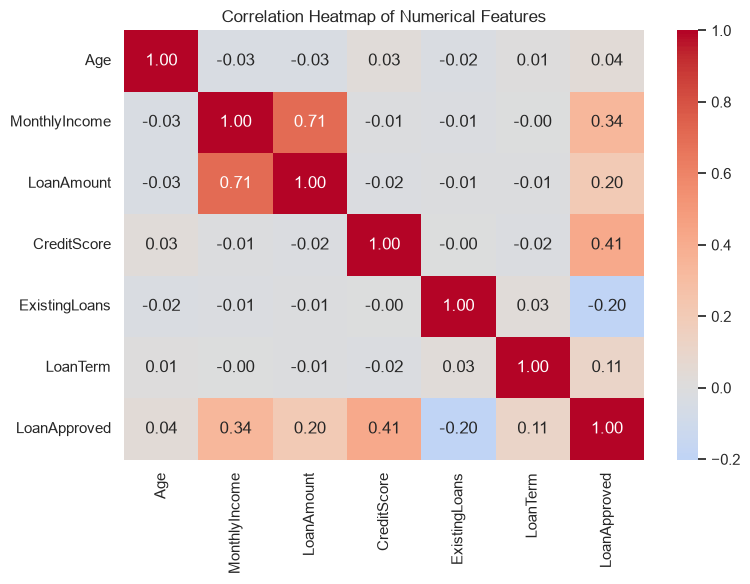

In [7]:
# Chart 2: Correlation heatmap
plt.figure(figsize=(8, 6))
numeric = df.drop(columns=["ApplicantID"]).select_dtypes("number")
sns.heatmap(numeric.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()

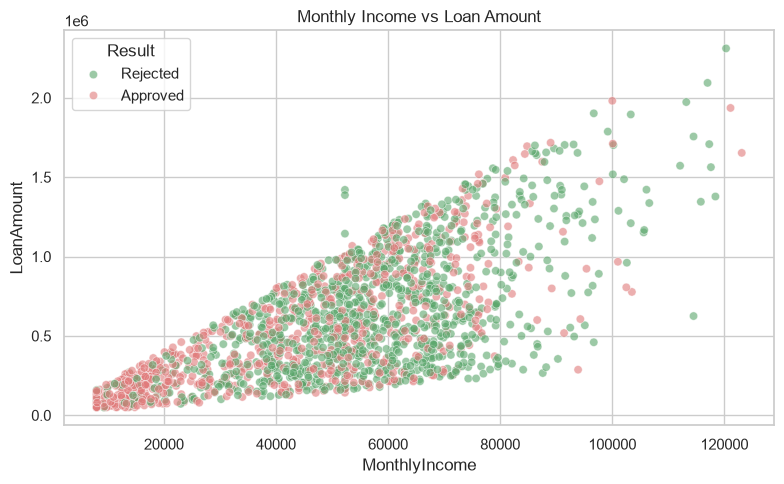

In [8]:
# Chart 3: Income vs loan amount
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="MonthlyIncome", y="LoanAmount", hue="LoanApproved",
                palette={0: "#e07b7b", 1: "#5aa66b"}, alpha=0.6)
plt.title("Monthly Income vs Loan Amount")
plt.legend(title="Result", labels=["Rejected", "Approved"])
plt.tight_layout()
plt.show()

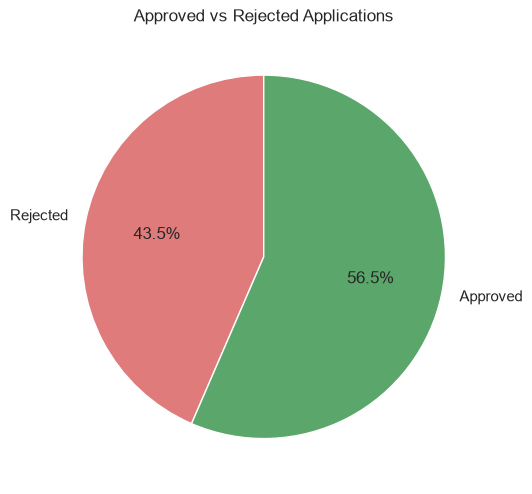

In [9]:
# Chart 4: Approved vs rejected pie chart
plt.figure(figsize=(5.5, 5.5))
counts = df["LoanApproved"].value_counts().sort_index()
plt.pie(counts, labels=["Rejected", "Approved"], autopct="%1.1f%%", colors=["#e07b7b", "#5aa66b"], startangle=90)
plt.title("Approved vs Rejected Applications")
plt.tight_layout()
plt.show()

## 6. Train and Compare Models
Data is split 80% training / 20% testing. Numbers are scaled and text columns are one-hot encoded inside a pipeline. Gender is **not** used, to keep decisions fair.

In [10]:
X = df.drop(columns=["ApplicantID", "LoanApproved", "Gender"])
y = df["LoanApproved"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print("Training rows:", len(X_train), "| Testing rows:", len(X_test))

numeric_cols = ["Age", "MonthlyIncome", "LoanAmount", "CreditScore", "ExistingLoans", "LoanTerm"]
text_cols = ["EmploymentStatus", "PropertyArea"]
preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numeric_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), text_cols),
])

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
}

results, trained = [], {}
for name, model in models.items():
    pipe = Pipeline([("prep", preprocessor), ("model", model)])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    trained[name] = (pipe, pred)
    results.append({"Model": name,
                    "Accuracy": accuracy_score(y_test, pred),
                    "Precision": precision_score(y_test, pred),
                    "Recall": recall_score(y_test, pred),
                    "F1-Score": f1_score(y_test, pred)})

results_df = pd.DataFrame(results).round(3)
results_df

Training rows: 1440 | Testing rows: 360


,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.794,0.803,0.842,0.822
1,Decision Tree,0.761,0.772,0.818,0.794
2,Random Forest,0.794,0.812,0.828,0.820


## 7. Evaluate the Best Model

Best model: Logistic Regression

              precision    recall  f1-score   support

    Rejected       0.78      0.73      0.76       157
    Approved       0.80      0.84      0.82       203

    accuracy                           0.79       360
   macro avg       0.79      0.79      0.79       360
weighted avg       0.79      0.79      0.79       360



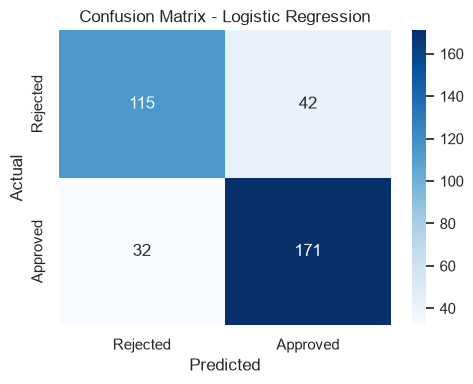

In [11]:
best_name = results_df.sort_values("F1-Score", ascending=False).iloc[0]["Model"]
best_pipe, best_pred = trained[best_name]
print("Best model:", best_name)
print()
print(classification_report(y_test, best_pred, target_names=["Rejected", "Approved"]))

cm = confusion_matrix(y_test, best_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Rejected", "Approved"], yticklabels=["Rejected", "Approved"])
plt.title("Confusion Matrix - " + best_name)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

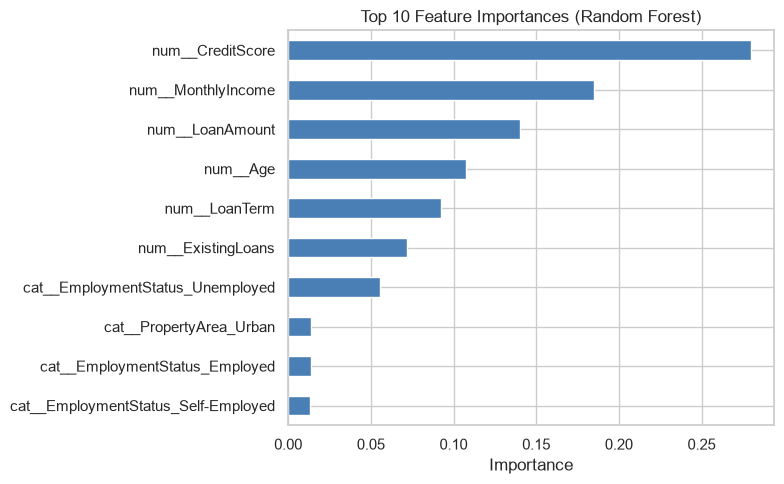

In [12]:
# Feature importance (Random Forest)
rf_pipe, _ = trained["Random Forest"]
names = rf_pipe.named_steps["prep"].get_feature_names_out()
importance = pd.Series(rf_pipe.named_steps["model"].feature_importances_, index=names).sort_values().tail(10)

plt.figure(figsize=(8, 5))
importance.plot(kind="barh", color="#4a7fb5")
plt.title("Top 10 Feature Importances (Random Forest)")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

## 8. Save the Model and Predict

In [13]:
joblib.dump(best_pipe, "loan_model.joblib")

def predict_loan(age, income, loan_amount, credit_score, employment, existing_loans, loan_term, area):
    applicant = pd.DataFrame([{
        "Age": age, "MonthlyIncome": income, "LoanAmount": loan_amount,
        "CreditScore": credit_score, "EmploymentStatus": employment,
        "ExistingLoans": existing_loans, "LoanTerm": loan_term, "PropertyArea": area}])
    result = best_pipe.predict(applicant)[0]
    chance = best_pipe.predict_proba(applicant)[0][1] * 100
    return ("APPROVED" if result == 1 else "REJECTED"), round(float(chance), 1)

print("Strong applicant:", predict_loan(30, 60000, 500000, 750, "Employed", 0, 60, "Urban"))
print("Weak applicant:  ", predict_loan(22, 9000, 2000000, 350, "Unemployed", 3, 240, "Rural"))

Strong applicant: ('APPROVED', 93.1)
Weak applicant:   ('REJECTED', 0.0)


## 9. Conclusion
- **Credit score** is the strongest factor: approval rises from about 20% (scores 300-600) to about 88% (scores 801-900).
- **Unemployed** applicants are approved far less often (about 14%) than employed ones (about 63-66%).
- Approved applicants have higher average income than rejected ones.
- Logistic Regression, Decision Tree and Random Forest were compared; the best model by F1-score is saved as `loan_model.joblib`.
- The console prediction system is in `predict_cli.py`.

*The data is synthetic and for learning only; do not use it for real lending decisions.*